# 1 · Fundamentos: fluxo de caixa, indicadores e RAU

Este notebook apresenta a biblioteca **greenseer** reproduzindo os exemplos das notas do curso
(Orçamento de Capital, Análise de Investimentos, *Cuidado com a TIR*). Cada número calculado aqui pode
ser conferido com os slides — é a forma de validar a ferramenta antes de usá-la no estudo de caso.

**Roteiro**

1. Do DRE ao fluxo de caixa global (FCG) e ao fluxo do capital próprio (FCCP)
2. Indicadores: VPL, payback ajustado, IBC, TIR, TIRM
3. Vidas úteis diferentes: empilhamento até o MMC, fluxo marginal e **RAU**
4. *Cuidado com a TIR*: múltiplas raízes e a hipótese de reinvestimento

In [1]:
import numpy as np
import pandas as pd

from greenseer import *
from greenseer import viz

viz.configurar_notebook()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Do DRE ao fluxo de caixa

A classe `Projeto` descreve um investimento pelas suas premissas (receitas, custos, depreciação, IR, valor
residual, capital de giro, financiamento) e monta a cadeia das notas de Orçamento de Capital:

```
Receitas → (−) Custos → EBITDA → (−) Depreciação → Lucro operacional → (−) IR → NOPAT
→ (+) Depreciação → FCO → (−) Investimento → (∓) Capital de giro → (+) Valor residual → FCG
```

**Exemplo dos slides** — projeto novo: custo $20.000 + instalação $8.000 (depreciação linear em 7 anos),
NCG $6.000, EBITDA $20.000/ano, IR 30%, valor residual de mercado $1.000 e financiamento de $15.000 a 10% a.a.
pelo sistema SAC em 5 anos.

In [2]:
novo = Projeto(
    "Projeto novo", vida_util=7,
    investimento=28_000,                      # 20.000 + 8.000 de instalação, em t = 0
    receitas=20_000, custos=0.0,              # EBITDA projetado constante
    aliquota_ir=0.30,
    capital_de_giro=6_000,                    # investido em t = 0 e recuperado no fim
    valor_residual=ValorResidual.mercado(1_000),
    financiamento=Financiamento(15_000, taxa=0.10, prazo=5, sistema="SAC"),
)
estilizar_demonstrativo(novo.demonstrativo(), "Projeto novo — DRE → FCG → FCCP")

ano,0,1,2,3,4,5,6,7
Projeto novo,,,,,,,,
Receitas,–,$ 20.000,$ 20.000,$ 20.000,$ 20.000,$ 20.000,$ 20.000,$ 20.000
(−) Custos e despesas,–,–,–,–,–,–,–,–
(=) EBITDA,–,$ 20.000,$ 20.000,$ 20.000,$ 20.000,$ 20.000,$ 20.000,$ 20.000
(−) Depreciação,–,$ 4.000,$ 4.000,$ 4.000,$ 4.000,$ 4.000,$ 4.000,$ 4.000
(=) Lucro operacional (EBIT),–,$ 16.000,$ 16.000,$ 16.000,$ 16.000,$ 16.000,$ 16.000,$ 16.000
(−) IR,–,$ 4.800,$ 4.800,$ 4.800,$ 4.800,$ 4.800,$ 4.800,$ 4.800
(=) NOPAT,–,$ 11.200,$ 11.200,$ 11.200,$ 11.200,$ 11.200,$ 11.200,$ 11.200
(+) Depreciação,–,$ 4.000,$ 4.000,$ 4.000,$ 4.000,$ 4.000,$ 4.000,$ 4.000
(=) Fluxo de caixa operacional,–,$ 15.200,$ 15.200,$ 15.200,$ 15.200,$ 15.200,$ 15.200,$ 15.200


O FCG de $15.200 e o fluxo do capital próprio ($11.150, $11.360, …) coincidem com os slides. No diagrama,
cada ano é decomposto em setas empilhadas: investimento e capital de giro para baixo no ano 0; no ano 7, a
recuperação do capital de giro e o valor residual líquido de IR ($1.000 − 30% × ganho = $700) empilham sobre o
fluxo operacional.

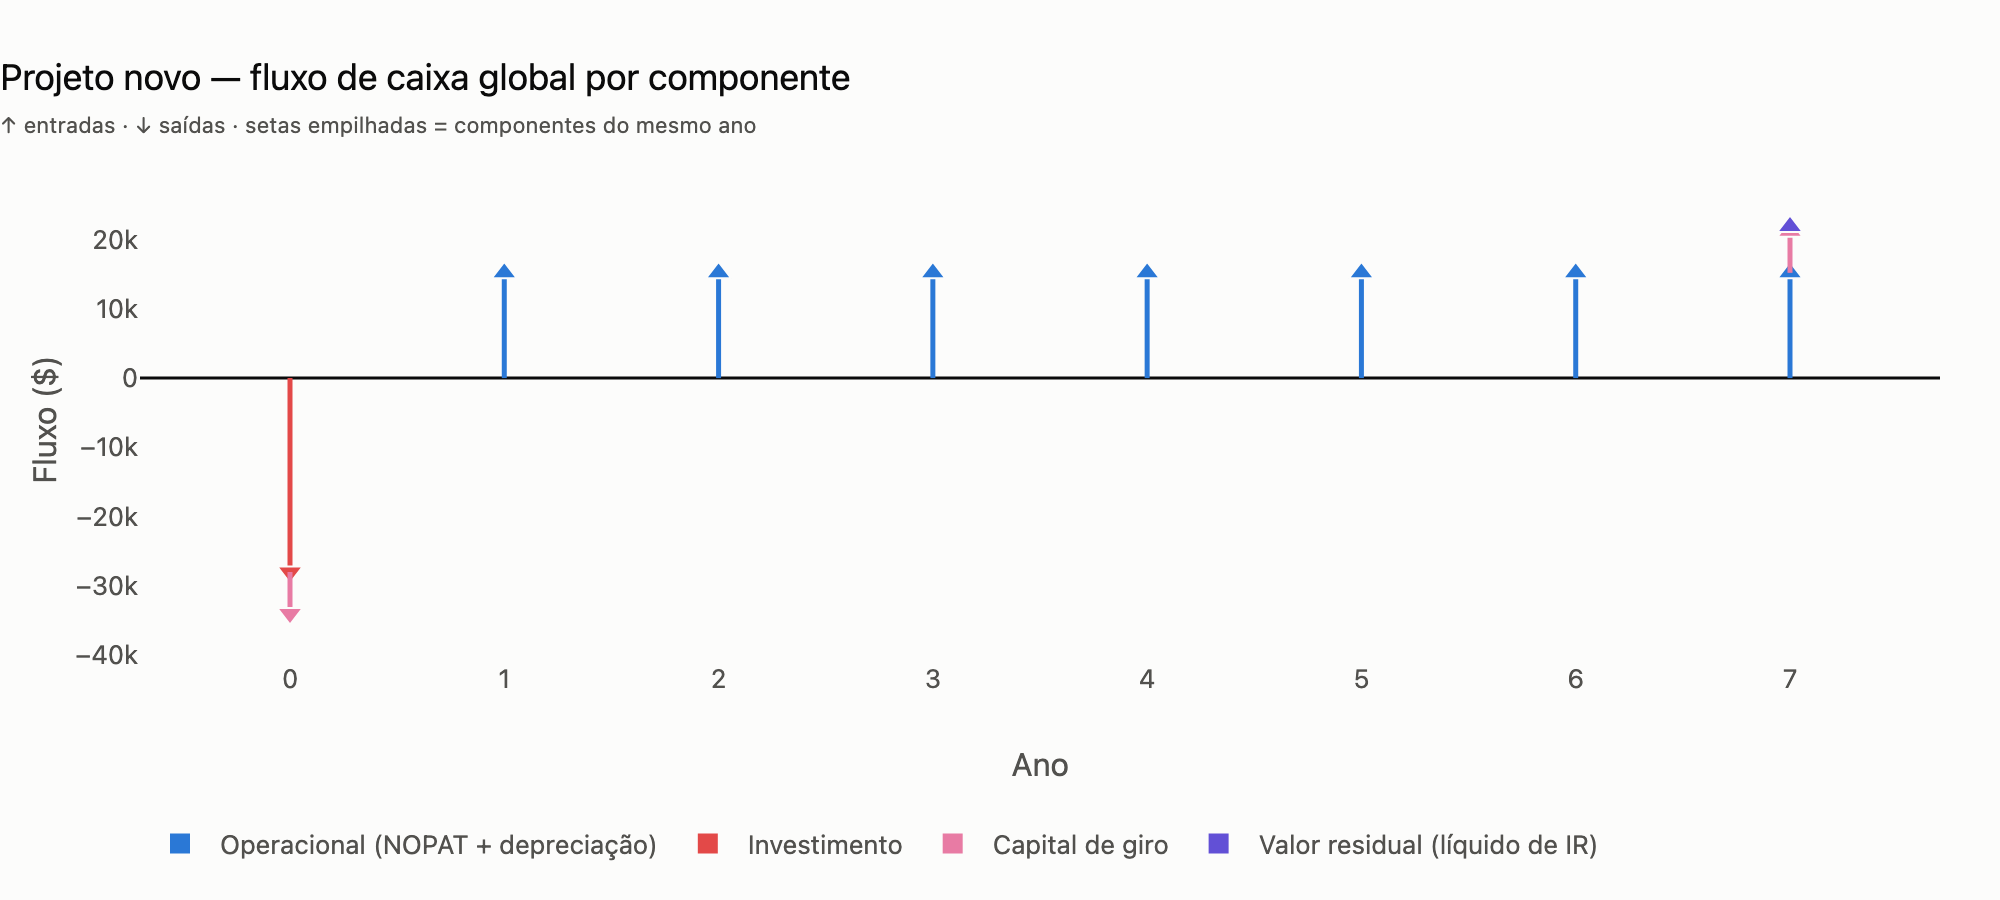

In [3]:
viz.grafico_fluxo(novo, titulo="Projeto novo — fluxo de caixa global por componente")

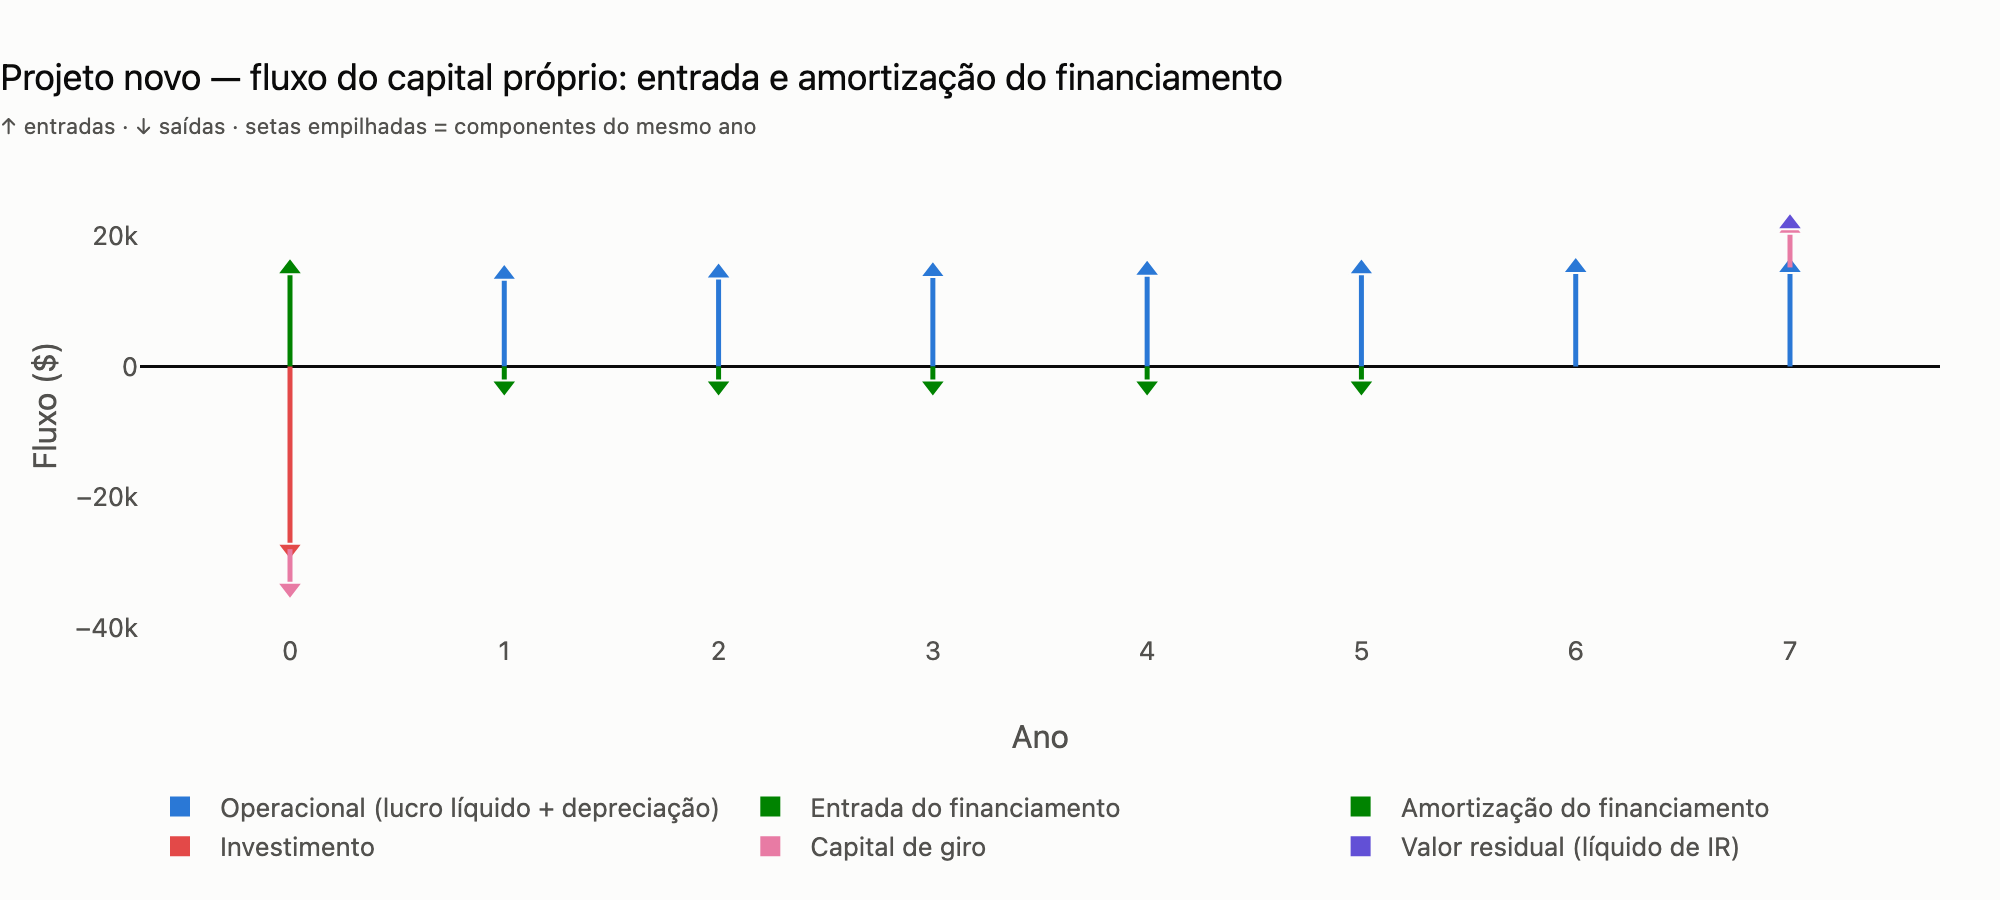

In [4]:
viz.grafico_fluxo(novo, tipo="proprio", titulo="Projeto novo — fluxo do capital próprio: entrada e amortização do financiamento")

A planilha do financiamento também fica disponível:

In [5]:
estilizar(novo.financiamento.tabela(7), tipos={c: "moeda" for c in ["Saldo inicial", "Juros", "Amortização", "Prestação", "Saldo final"]}, destacar=[])

,Saldo inicial,Juros,Amortização,Prestação,Saldo final
ano,,,,,
0,$ 0,$ 0,$ 0,$ 0,$ 15.000
1,$ 15.000,$ 1.500,$ 3.000,$ 4.500,$ 12.000
2,$ 12.000,$ 1.200,$ 3.000,$ 4.200,$ 9.000
3,$ 9.000,$ 900,$ 3.000,$ 3.900,$ 6.000
4,$ 6.000,$ 600,$ 3.000,$ 3.600,$ 3.000
5,$ 3.000,$ 300,$ 3.000,$ 3.300,$ 0
6,$ 0,$ 0,$ 0,$ 0,$ 0
7,$ 0,$ 0,$ 0,$ 0,$ 0


### Fluxo marginal (novo − anterior)

O projeto anterior (ativo já existente) tem EBITDA decrescente e depreciação de $1.000/ano. O que interessa na
decisão de substituição é o **fluxo marginal** — e o mesmo mecanismo serve para comparar dois projetos quaisquer.

In [6]:
anterior = Projeto(
    "Projeto anterior", vida_util=7, investimento=0.0,
    receitas=[18_000, 16_000, 16_000, 15_000, 15_000, 13_000, 13_000], aliquota_ir=0.30, depreciacao=1_000,
)
marginal = fluxo_marginal(anterior, novo, metodo="estender")
pd.DataFrame({"Novo (FCG)": novo.fluxo().valores, "Anterior (FCG)": anterior.fluxo().valores, "Marginal": marginal.valores},
             index=pd.Index(range(8), name="ano")).T.style.format("{:,.0f}")

ano,0,1,2,3,4,5,6,7
Novo (FCG),"-34,000","15,200","15,200","15,200","15,200","15,200","15,200","21,900"
Anterior (FCG),0,"12,900","11,500","11,500","10,800","10,800","9,400","9,400"
Marginal,"-34,000","2,300","3,700","3,700","4,400","4,400","5,800","12,500"


## 2. Indicadores de avaliação

Exemplo dos slides de Análise de Investimentos: projetos A e B, WACC = 10%.

In [7]:
K = 0.10
A = FluxoDeCaixa([-60_000] + [20_000] * 6, "A")
B = FluxoDeCaixa([-72_000, 45_000, 22_000, 20_000, 13_000, 13_000, 13_000], "B")
estilizar(tabela_indicadores([A, B], K), titulo="Indicadores a 10% a.a. (slides: VPL 27.080 / 26.381, payback 3,75 / 2,86, IBC 1,45 / 1,37)")

,Investimento,Vida (anos),VPL,TIR,TIRM,RAU,IBC,ROIA,Payback simples,Payback ajustado
Projeto,,,,,,,,,,
A,$ 60.000,6,$ 27.105,"24,29%","17,05%",$ 6.224,"1,45","6,41%","3,00 anos","3,75 anos"
B,$ 72.000,6,$ 26.407,"26,06%","15,88%",$ 6.063,"1,37","5,35%","2,25 anos","2,86 anos"


As pequenas diferenças em relação aos slides vêm do arredondamento dos fatores de valor atual (3 casas) usado
em sala. O gráfico abaixo mostra o fluxo e o acumulado descontado, com o ponto de payback ajustado:

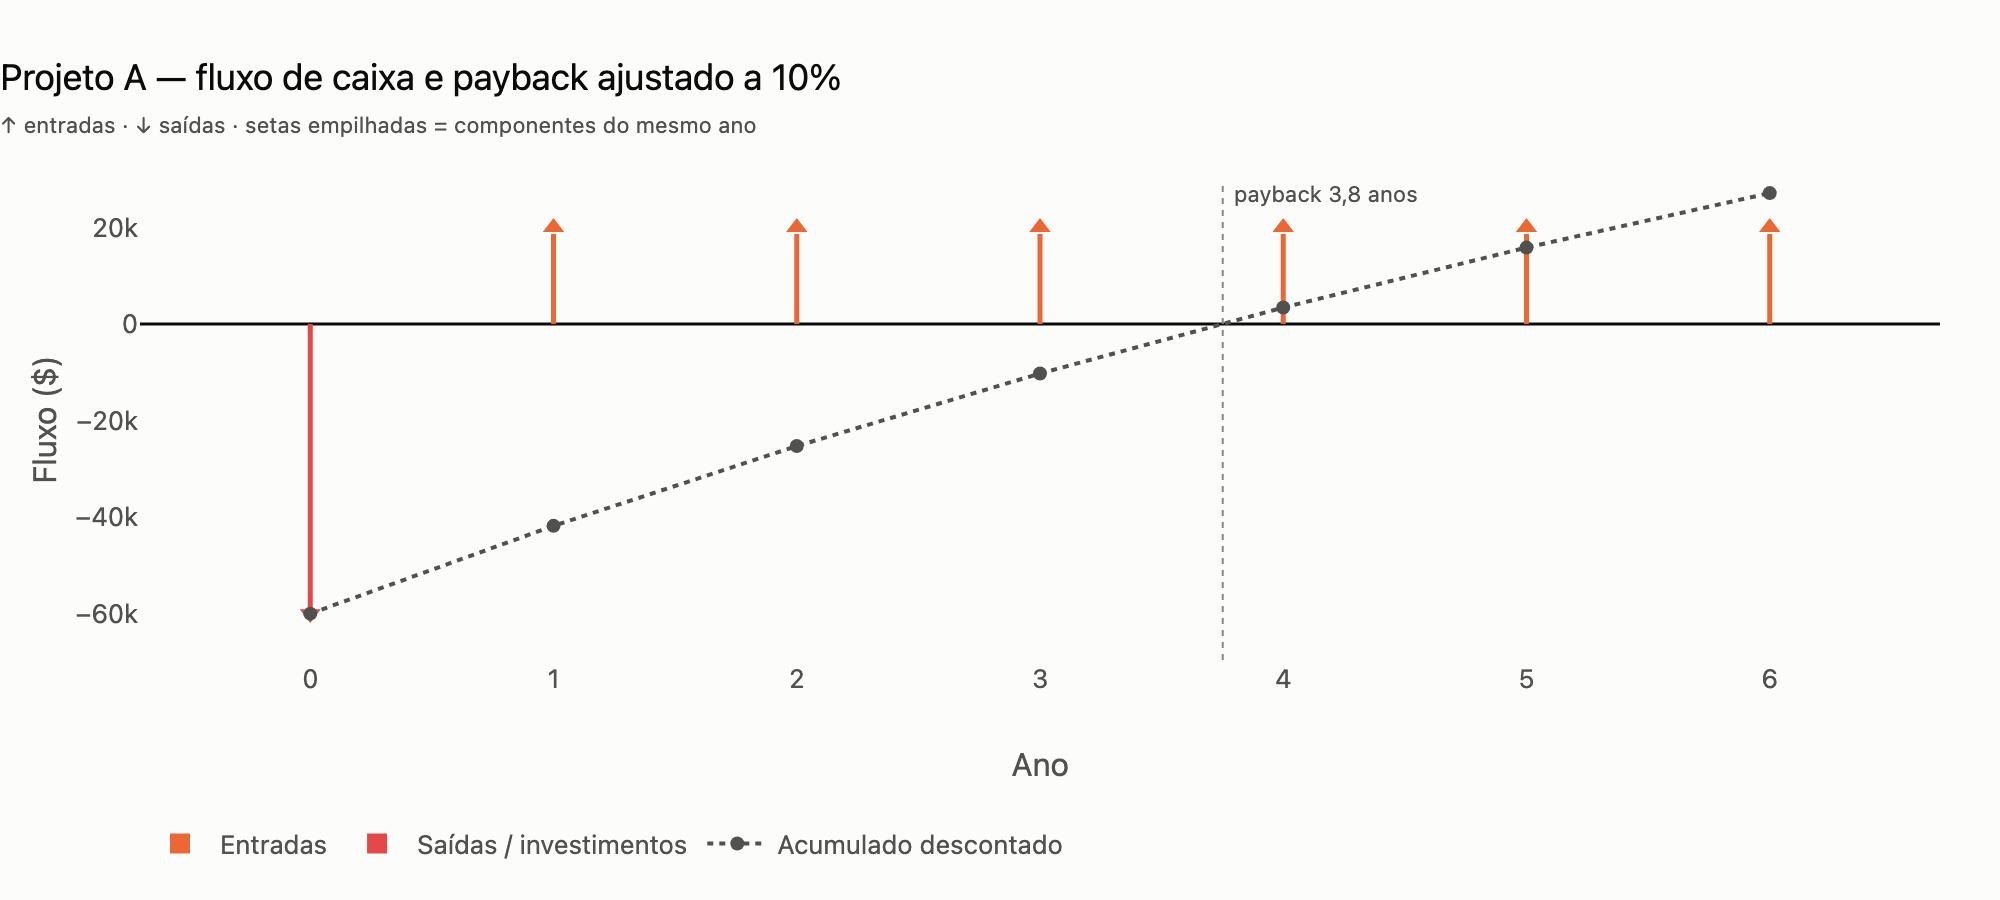

In [8]:
viz.grafico_fluxo(A, taxa=K, acumulado=True, titulo="Projeto A — fluxo de caixa e payback ajustado a 10%")

Cada indicador também existe como função isolada (`vpl`, `tir`, `tirm`, `payback`, `ibc`, `rau`, `roia`,
`taxa_fisher`). Todas aceitam um `FluxoDeCaixa`, um `Projeto` ou um array:

In [9]:
print(f"VPL(A) = {vpl(A, K):,.0f}   TIR(A) = {tir(A):.2%}   payback ajustado = {payback(A, K):.2f} anos   IBC = {ibc(A, K):.3f}")
print(f"VPL(B) = {vpl(B, K):,.0f}   TIR(B) = {tir(B):.2%}   payback ajustado = {payback(B, K):.2f} anos   IBC = {ibc(B, K):.3f}")

VPL(A) = 27,105   TIR(A) = 24.29%   payback ajustado = 3.75 anos   IBC = 1.452
VPL(B) = 26,407   TIR(B) = 26.06%   payback ajustado = 2.86 anos   IBC = 1.367


## 3. Vidas úteis diferentes: empilhamento, fluxo marginal e RAU

Segundo exemplo dos slides: A (4 anos) e B (6 anos). Comparar VPLs de horizontes diferentes é inadequado.
As notas mostram dois caminhos equivalentes:

* **Empilhar** cada projeto até o mínimo múltiplo comum das vidas (12 anos), montar o fluxo marginal B − A
  e calcular a TIR marginal;
* calcular o **RAU** (Resultado Anual Uniforme) = equivalente anual uniforme do fluxo − equivalente anual
  uniforme do investimento = VPL × (A/P, i, n).

In [10]:
A2 = FluxoDeCaixa([-64_000] + [21_000] * 4, "A")
B2 = FluxoDeCaixa([-122_000, 29_000, 28_000, 27_000, 26_000, 25_000, 44_000], "B")
tab = tabela_indicadores([A2, B2], K)
estilizar(tab[["investimento", "vida", "vpl", "tir", "rau"]], titulo="A tem a maior TIR; B tem o maior RAU (slides: 810 vs. 1.351)")

,Investimento,Vida (anos),VPL,TIR,RAU
Projeto,,,,,
A,$ 64.000,4,$ 2.567,"11,84%",$ 810
B,$ 122.000,6,$ 5.908,"11,56%",$ 1.356


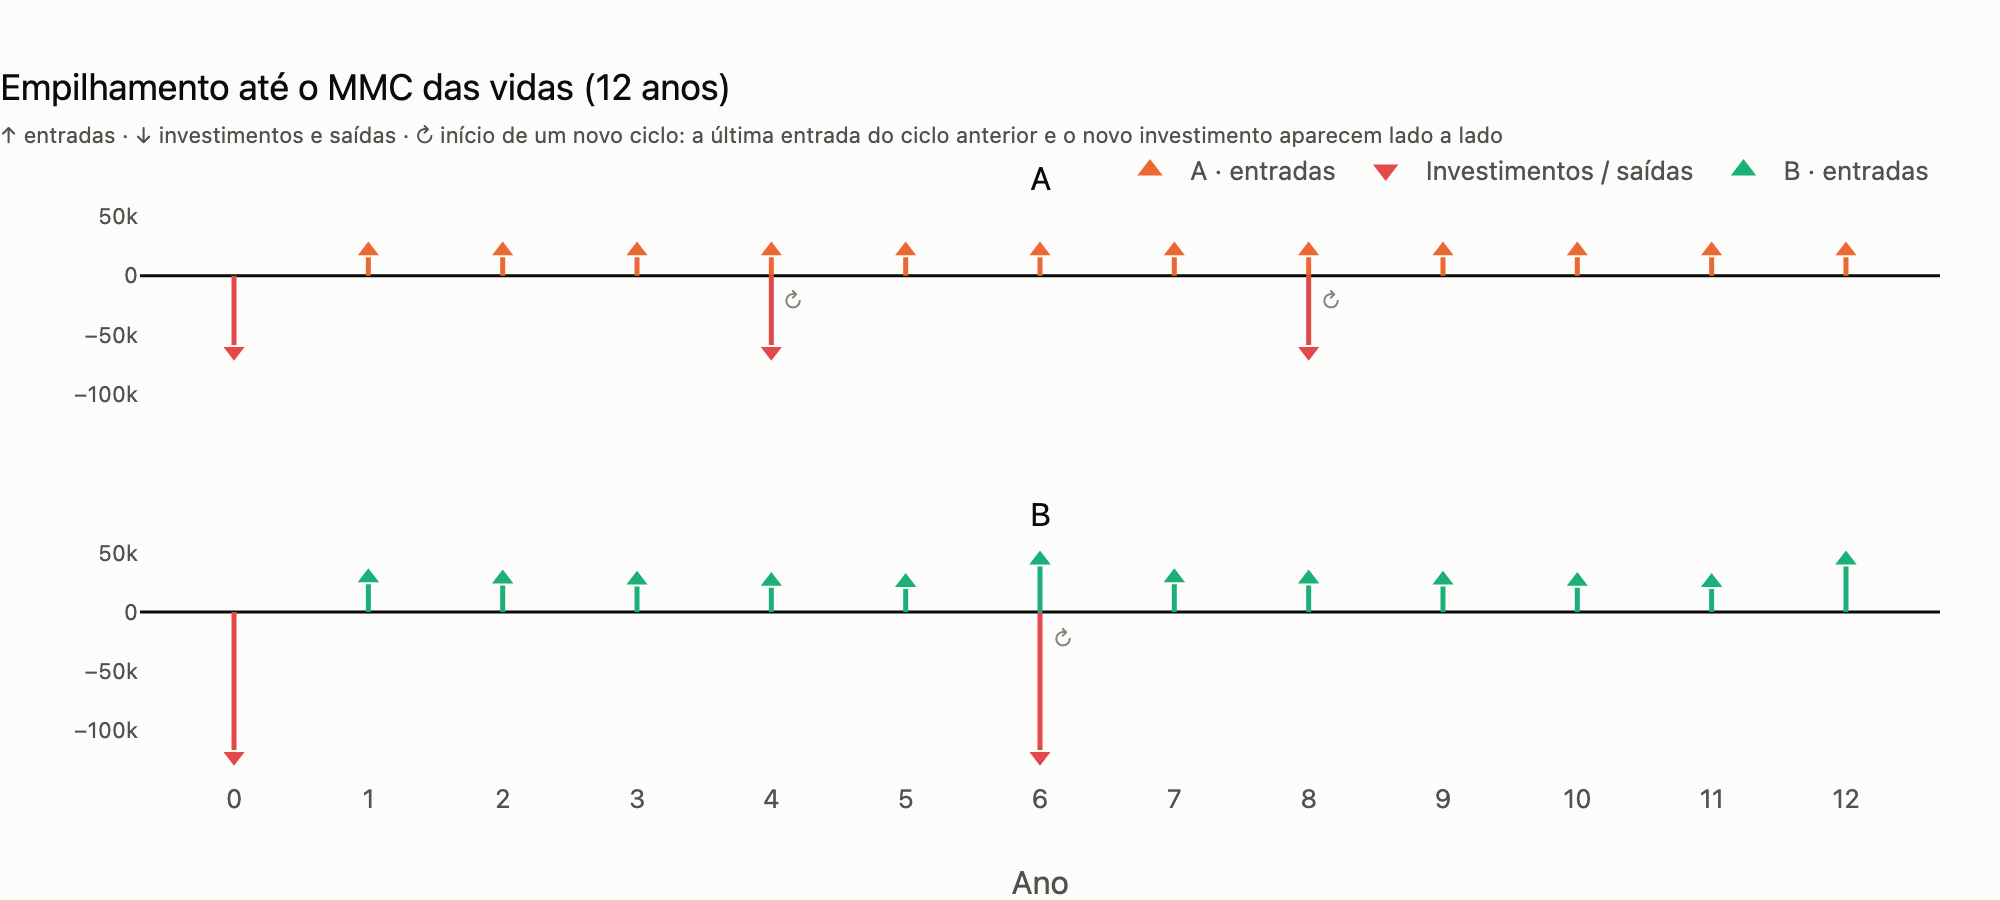

In [11]:
viz.grafico_fluxos_empilhados([A2, B2], metodo="mmc", titulo="Empilhamento até o MMC das vidas (12 anos)")

In [12]:
marg = fluxo_marginal(A2, B2, metodo="mmc")
print("Fluxo marginal B − A (12 anos):", np.round(marg.valores / 1000, 1), "(em $ mil)")
print(f"TIR marginal = {tir(marg):.2%}  (slides: 11,33% por interpolação)  >  WACC 10%  ⇒  B é preferível")
print(f"VPL marginal a 10% = {vpl(marg, K):,.0f}   |   RAU(B) − RAU(A) = {rau(B2, K) - rau(A2, K):,.0f}   |   RAU do fluxo marginal = {rau(marg, K):,.0f}")

Fluxo marginal B − A (12 anos): [-58.   8.   7.   6.  69.   4. -99.   8.  71.   6.   5.   4.  23.] (em $ mil)
TIR marginal = 11.28%  (slides: 11,33% por interpolação)  >  WACC 10%  ⇒  B é preferível
VPL marginal a 10% = 3,725   |   RAU(B) − RAU(A) = 547   |   RAU do fluxo marginal = 547


Repare que o **RAU é invariante ao empilhamento**: o RAU de A sobre 12 anos (três ciclos) é o mesmo RAU de um
ciclo de 4 anos. Por isso ele é o atalho correto para comparar vidas diferentes sob a hipótese de repetição —
e o VPL marginal do empilhamento é exatamente o valor presente da diferença de RAU.

In [13]:
print(f"RAU(A, 1 ciclo) = {rau(A2, K):,.2f}   RAU(A, 3 ciclos) = {rau(A2.replicar(3), K):,.2f}")
print(f"RAU(B, 1 ciclo) = {rau(B2, K):,.2f}   RAU(B, 2 ciclos) = {rau(B2.replicar(2), K):,.2f}")

RAU(A, 1 ciclo) = 809.87   RAU(A, 3 ciclos) = 809.87
RAU(B, 1 ciclo) = 1,356.49   RAU(B, 2 ciclos) = 1,356.49


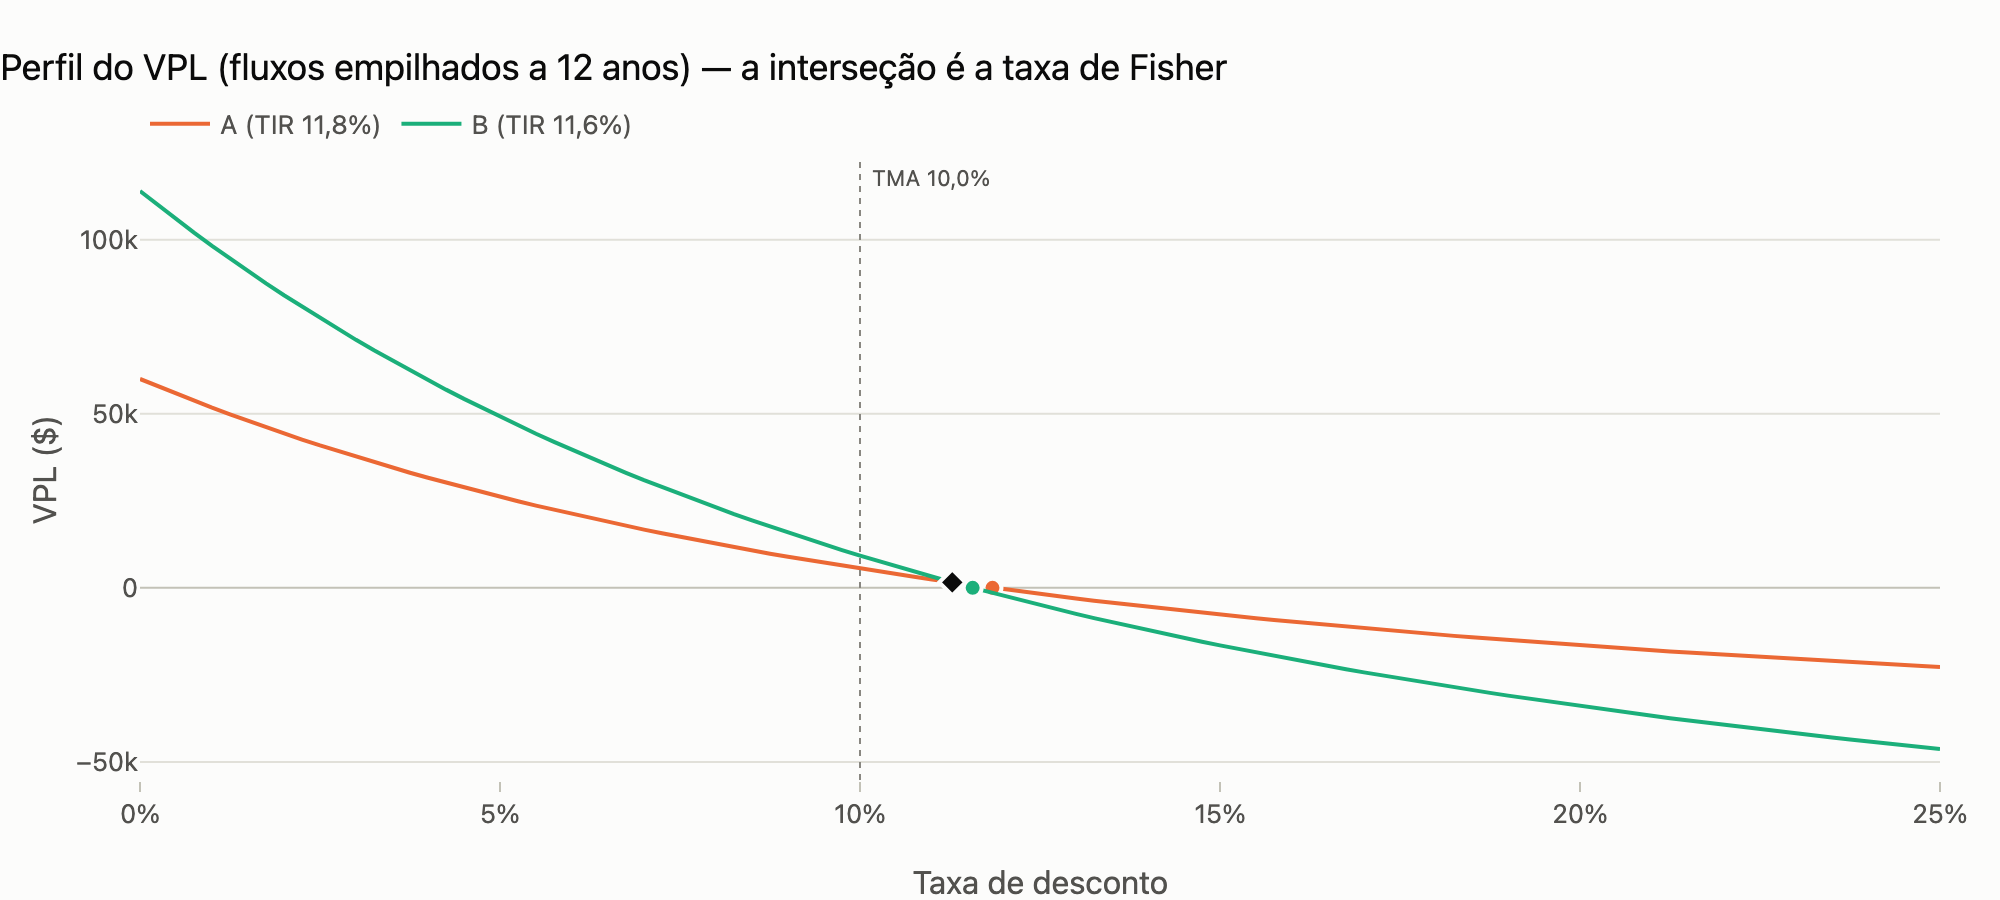

In [14]:
viz.grafico_perfil_vpl([A2, B2], K, taxas=np.linspace(0, 0.25, 101), metodo="mmc",
                       titulo="Perfil do VPL (fluxos empilhados a 12 anos) — a interseção é a taxa de Fisher")

A função `analise_marginal` faz esse procedimento para **todos os pares** de uma lista de projetos (ordenando
por investimento, defensor × desafiante) — é o que faltou na resolução de referência do estudo de caso e o que
veremos no próximo notebook.

## 4. *Cuidado com a TIR*

A TIR supõe que os fluxos intermediários são reinvestidos à própria TIR. A **TIRM** troca essa hipótese por
uma taxa de reinvestimento explícita (o custo de capital). Exemplo dos slides: investimento de $180.000 e
TIR de 32%; com reinvestimento a 25% a TIRM cai para 29,6%, e a 18% para 27,0%.

In [15]:
T = FluxoDeCaixa([-180_000, 26_200, 61_200, 138_200, 103_200, 129_200], "T")
print(f"TIR = {tir(T):.2%}   TIRM (reinv. 25%) = {tirm(T, 0.25):.2%}   TIRM (reinv. 18%) = {tirm(T, 0.18):.2%}")

TIR = 32.30%   TIRM (reinv. 25%) = 29.58%   TIRM (reinv. 18%) = 27.00%


Fluxos não convencionais (mais de uma inversão de sinal) podem ter **várias TIR** — o caso típico é um fluxo
marginal entre projetos empilhados. `tir(..., todas=True)` devolve todas as raízes; a decisão deve usar o sinal
do VPL marginal à TMA, não "a" TIR:

Raízes: ['10.0%', '20.0%'] | VPL a 15% = 0.189


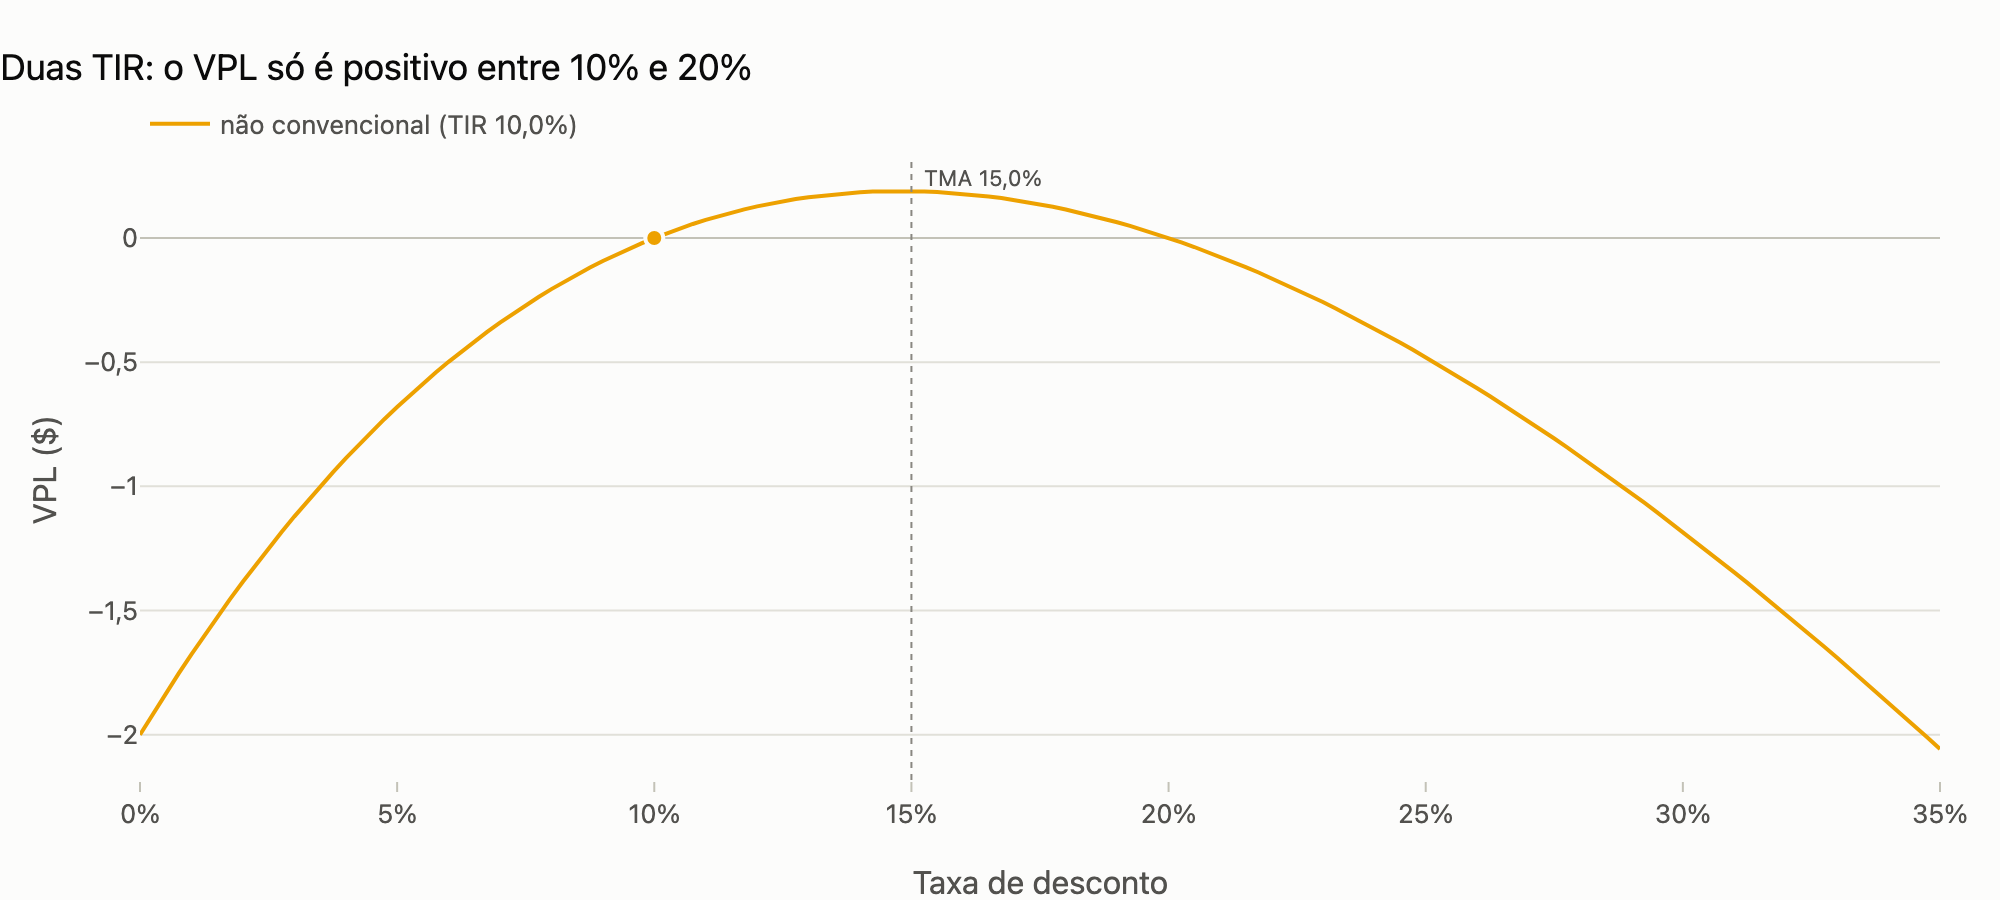

In [16]:
nc = FluxoDeCaixa([-100, 230, -132], "não convencional")
print("Raízes:", [f"{r:.1%}" for r in tir(nc, todas=True)], "| VPL a 15% =", round(vpl(nc, 0.15), 3))
viz.grafico_perfil_vpl([nc], 0.15, taxas=np.linspace(0, 0.35, 141), fisher=False, titulo="Duas TIR: o VPL só é positivo entre 10% e 20%")

## Resumo da API

| Tarefa | Função / classe |
|---|---|
| Descrever premissas e obter o fluxo | `Projeto(...)`, `.demonstrativo()`, `.fluxo("global"/"proprio")` |
| Séries flexíveis | `Crescimento`, `Variacoes`, `Percentual`, `Produto`, `Soma`, `Degraus` |
| Indicadores | `vpl`, `vp`, `tir`, `tirm`, `payback`, `ibc`, `rau`, `roia`, `taxa_fisher`, `tabela_indicadores` |
| Vidas diferentes / marginal | `equalizar`, `fluxo_marginal`, `analise_marginal`, `matriz_marginal`, `campeao_incremental` |
| Carteiras | `carteiras(fluxos, taxa, k=2, orcamento=...)` |
| Risco | `Cenario`, `AnaliseDeCenarios`, `sensibilidade`, `ponto_de_equilibrio`, `MonteCarlo` |
| Apresentação | `viz.grafico_*`, `viz.exportar`, `estilizar`, `estilizar_demonstrativo` |